# 42 — DEMON e augmentation com fundo de mar agitado

**Pergunta.** No LOFAR (NB41), misturar ruído real de mar agitado nos LARGE de treino não ajudou: o ruído apagava o grave que identifica o LARGE. O **DEMON** mede outra coisa — os ritmos de modulação da cavitação (rotação do eixo, passagem das pás) na banda de 1–2 kHz, justamente onde o ruído de vento e ondas mais cresce. Será que o DEMON aproveita esse augmentation?

Notebook separado dos experimentos de LOFAR para não misturar os resultados.

**Resumo das respostas:**
1. **O DEMON sozinho é bem mais fraco que o LOFAR** na mesma MLP: SP 45,7 contra 56,1 no split por navio. Ele separa bem o BACKGROUND e razoavelmente o LARGE, mas SMALL fica perto do acaso.
2. **O augmentation com mar agitado também não ajuda no DEMON:** recall de LARGE 60,8% → 56,2% no split por navio; nenhuma diferença significativa (menor p = 0,13).
3. **O mecanismo é o mesmo do LOFAR:** o ruído deixa as linhas de modulação mais rasas. Com muito ruído (0–5 dB), 61% das cópias de LARGE ficam com o contraste de um navio < 100 m.

## Glossário rápido

- **DEMON (*Demodulation of Envelope Modulation On Noise*):** filtra o áudio numa banda (aqui 1–2 kHz), tira o envelope e calcula o espectro desse envelope. Picos em poucos Hz indicam rotação do eixo e passagem das pás do hélice.
- **Janela do DEMON no IARA:** 10,24 s, a cada 5,12 s; 253 frequências de modulação de 0,4 a 25 Hz.
- **Contraste do DEMON:** quanto o pico do espectro DEMON sobressai da sua mediana (dB). Linhas de modulação marcadas = contraste alto.
- **Augmentation:** versão modificada de uma gravação de treino; aqui, o áudio do LARGE somado a uma gravação real de mar sem navio.
- **Split por navio:** nenhum navio aparece no treino e no teste ao mesmo tempo.
- **Valor-p (teste F 5x2cv):** abaixo de 0,05, a diferença entre dois métodos provavelmente é real.

In [1]:
import os, sys, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
try:
    from IPython.display import display
except ImportError:
    display = print
for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.precision', 1); pd.set_option('display.width', 200)

CN = {0: 'SMALL', 1: 'MEDIUM', 2: 'LARGE', 3: 'BACKGROUND'}
COR = {'SMALL': '#2a78d6', 'MEDIUM': '#eb6834', 'LARGE': '#1baf7a', 'BACKGROUND': '#8a8a8a'}
meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'), dtype={'Ship ID': str, 'ID': str})
meta = meta[meta.Dataset.isin(list('ABCDE'))].copy()
meta.index = meta.ID.astype(int)
meta['Length'] = pd.to_numeric(meta.Length, errors='coerce')
meta['Target'] = np.select([meta.Length < 50, meta.Length < 100, meta.Length >= 100], [0, 1, 2], default=3)
meta.loc[meta.Dataset == 'E', 'Target'] = 3
meta['Mar'] = pd.to_numeric(meta['Sea state'], errors='coerce')
meta['CPA'] = meta.Dataset.isin(['A', 'C'])

with open(os.path.join(R.ROOT, 'data/iara_processed/cache_fusion_mel_demon.pkl'), 'rb') as fh:
    DEMON = pickle.load(fh)['demon']
FD = (np.arange(253) + 4) * 50 / 512   # frequências de modulação (Hz)
print(f'DEMON: {len(DEMON)} gravações; janela de 10,24 s a cada 5,12 s; {len(FD)} frequências de {FD[0]:.2f} a {FD[-1]:.1f} Hz')

DEMON: 1706 gravações; janela de 10,24 s a cada 5,12 s; 253 frequências de 0.39 a 25.0 Hz


## 1. Como é o DEMON de cada classe

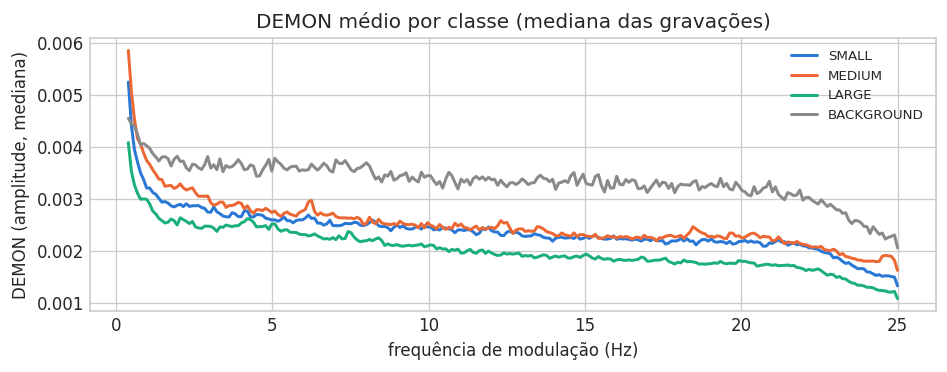

Contraste do DEMON médio da gravação (pico / mediana, dB), mediana por classe:


,contraste_dB
Target,
SMALL,9.4
MEDIUM,9.7
LARGE,12.0
BACKGROUND,3.9


In [2]:
media = pd.DataFrame({f: w.mean(0) for f, w in DEMON.items()}).T
media['Target'] = meta.Target.reindex(media.index)
fig, ax = plt.subplots(figsize=(8, 3.2))
for c, n in CN.items():
    ax.plot(FD, media[media.Target == c].drop(columns='Target').median().values, color=COR[n], lw=1.8, label=n)
ax.set_xlabel('frequência de modulação (Hz)'); ax.set_ylabel('DEMON (amplitude, mediana)')
ax.set_title('DEMON médio por classe (mediana das gravações)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

def contraste(w):
    s = w.mean(0)
    return 20 * np.log10(s.max() / np.median(s))
CONTR = pd.Series({f: contraste(w) for f, w in DEMON.items()}).to_frame('contraste_dB').join(meta.Target)
CONTR_CLASSE = CONTR.groupby(CONTR.Target.map(CN)).contraste_dB.median().reindex(list(CN.values()))
print('Contraste do DEMON médio da gravação (pico / mediana, dB), mediana por classe:'); display(CONTR_CLASSE.round(1).to_frame())

**Leitura.** Os LARGE têm o DEMON mais "marcado" (contraste 12,0 dB), os navios menores um pouco menos, e o BACKGROUND quase nada (3,9 dB): sem navio, o envelope do ruído não tem ritmo.

## 2. Referência: DEMON × LOFAR na mesma MLP

Mesma MLP h32-16 do NB29, mesmos folds, 4 classes, sem augmentation. A previsão de cada gravação é o voto majoritário das janelas.

In [3]:
def metricas(y, p):
    rec = np.array([np.mean(p[y == c] == c) for c in range(4)])
    sp = np.sqrt(rec.mean() * np.exp(np.mean(np.log(rec)))) * 100 if np.all(rec > 0) else 0.0
    return {'SP': sp, 'ACC': rec.mean() * 100, **{f'R_{CN[c]}': r * 100 for c, r in enumerate(rec)}}

def por_fold(exp):
    P = R.file_predictions(exp)
    return pd.DataFrame({k: metricas(d.Target.values, d.Prediction.values) for k, d in P.items()}).T

REF = {}
for cond, nome in [('split_navio', 'por navio'), ('split_id', 'por gravação')]:
    REF[('LOFAR', nome)] = por_fold(f'{cond}_mlp_lofar_4c').mean()
    REF[('DEMON', nome)] = por_fold(f'demon_mar_{cond}_mlp_demon_4c').mean()
REF = pd.DataFrame(REF).T
print('MLP h32-16, 4 classes, mesmos folds, sem augmentation (média de 10 folds):'); display(REF.round(1))

MLP h32-16, 4 classes, mesmos folds, sem augmentation (média de 10 folds):


,,SP,ACC,R_SMALL,R_MEDIUM,R_LARGE,R_BACKGROUND
LOFAR,por navio,56.1,58.3,49.8,34.5,67.7,81.1
DEMON,por navio,45.7,49.4,28.2,32.4,60.8,76.3
LOFAR,por gravação,67.4,67.8,54.1,65.9,71.2,80.0
DEMON,por gravação,52.8,54.3,33.8,46.3,65.1,72.2


**Leitura.** O DEMON sozinho fica bem abaixo do LOFAR (SP 45,7 × 56,1 no split por navio). SMALL fica perto do acaso (28%). Hipótese (não testada): lanchas e rebocadores pequenos têm modulação menos marcada na banda de 1–2 kHz.

## 3. Como o augmentation foi feito

- **As mesmas misturas do LOFAR** (`scripts/extrair_demon_mixbg_mar.py`): para cada cópia de LARGE, o mesmo fundo, o mesmo deslocamento e a mesma razão sinal/fundo (0 a 20 dB) usados no NB41; o DEMON é recalculado com os parâmetros do pipeline. Sem mistura, o script reproduz o DEMON original (diferença máxima ~10⁻⁹). O DEMON original não é alterado: pastas novas.
- **No treino** de cada fold, cada LARGE ganha uma versão extra, só com fundos do treino daquele fold. **Teste** sempre no DEMON original.
- **Variantes:** fundo de mar agitado (estado ≥ 4, sem chuva) e dois controles — fundo de mar calmo (≤ 2) e LARGE duplicado (só repetição).

## 4. Resultado

DEMON — médias de 10 folds:


SP   ACC  R_SMALL  R_MEDIUM  R_LARGE  R_BACKGROUND
split_navio sem augmentation                       45.7  49.4     28.2      32.4     60.8          76.3
            LARGE duplicado (controle)             42.8  47.9     29.6      25.9     60.4          75.7
            LARGE + fundo de mar calmo (controle)  43.8  48.3     27.5      29.5     58.9          77.2
            LARGE + fundo de mar agitado           43.7  48.0     33.0      29.1     56.2          73.9
split_id    sem augmentation                       52.8  54.3     33.8      46.3     65.1          72.2
            LARGE duplicado (controle)             53.4  55.2     32.8      48.4     62.9          76.9
            LARGE + fundo de mar calmo (controle)  52.2  54.0     32.4      46.4     61.3          76.1
            LARGE + fundo de mar agitado           52.8  54.4     34.4      46.8     63.1          73.1

Diferenças contra "sem augmentation" (F 5x2cv):


,split,variante,métrica,Δ vs base,folds melhores,p (F 5x2cv)
0,split_navio,dupL,SP,-2.9e+00,2,1.3e-01
1,split_navio,dupL,ACC,-1.5e+00,4,1.2e-02
2,split_navio,dupL,R_LARGE,-4.5e-01,6,3.1e-01
3,split_navio,dupL,R_SMALL,1.4e+00,5,6.8e-01
4,split_navio,dupL,R_MEDIUM,-6.5e+00,2,3.8e-01
5,split_navio,dupL,R_BACKGROUND,-6.2e-01,5,6.8e-01
6,split_navio,calmo,SP,-1.8e+00,3,1.3e-01
7,split_navio,calmo,ACC,-1.2e+00,3,3.7e-01
8,split_navio,calmo,R_LARGE,-1.9e+00,5,7.6e-01
9,split_navio,calmo,R_SMALL,-6.4e-01,4,3.4e-01


Acerto de LARGE (%) por CPA × estado do mar, split por navio:


sem augmentation  LARGE duplicado (controle)  LARGE + fundo de mar calmo (controle)  LARGE + fundo de mar agitado
cpa            mar                                                                                                                            
com CPA (A, C) agitado (3+)              59.0                        60.0                                   60.0                          56.0
               calmo (0–2)               69.0                        68.0                                   65.0                          63.0
sem CPA (B, D) agitado (3+)              51.0                        47.0                                   46.0                          49.0
               calmo (0–2)               52.0                        54.0                                   53.0                          47.0

LOFAR × DEMON, split por navio (ACC e recall de LARGE):


LOFAR         DEMON        
                                        ACC R_LARGE   ACC R_LARGE
sem augmentation                       58.3    67.7  49.4    60.8
LARGE duplicado (controle)             58.3    67.6  47.9    60.4
LARGE + fundo de mar calmo (controle)  57.6    63.3  48.3    58.9
LARGE + fundo de mar agitado           57.7    65.4  48.0    56.2

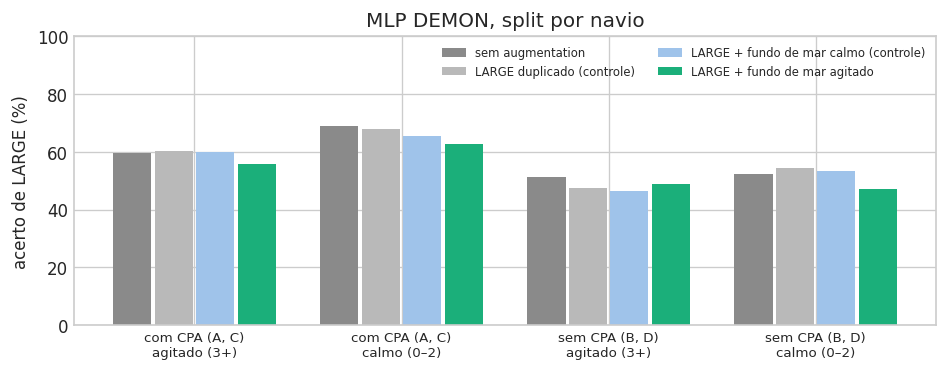

In [4]:
VAR = {'base': 'sem augmentation', 'dupL': 'LARGE duplicado (controle)', 'calmo': 'LARGE + fundo de mar calmo (controle)',
       'agitado': 'LARGE + fundo de mar agitado'}
def exp(cond, v, rep='demon'):
    b = f'demon_mar_{cond}_mlp_demon_4c' if rep == 'demon' else f'{cond}_mlp_lofar_4c'
    return b + ('' if v == 'base' else f'_aug{v}')
FMA = {(c, v): por_fold(exp(c, v)) for c in ['split_navio', 'split_id'] for v in VAR}
MEDIAS = pd.concat({(c, VAR[v]): f.mean() for (c, v), f in FMA.items()}, axis=1).T
print('DEMON — médias de 10 folds:'); display(MEDIAS.round(1))
rows = []
for cond in ['split_navio', 'split_id']:
    for v in ['dupL', 'calmo', 'agitado']:
        A, B = FMA[(cond, v)], FMA[(cond, 'base')]
        for m in ['SP', 'ACC', 'R_LARGE', 'R_SMALL', 'R_MEDIUM', 'R_BACKGROUND']:
            rows.append({'split': cond, 'variante': v, 'métrica': m, 'Δ vs base': (A[m] - B[m]).mean(),
                         'folds melhores': int((A[m] > B[m]).sum()), 'p (F 5x2cv)': R.f_test_5x2(A[m].values, B[m].values)[1]})
DELTA = pd.DataFrame(rows)
print('Diferenças contra "sem augmentation" (F 5x2cv):'); display(DELTA.round(3))

# LARGE por CPA × estado do mar, split por navio
def estratos(exp_name):
    d = pd.concat(R.file_predictions(exp_name).values(), ignore_index=True)
    d['File'] = d.File.astype(int); d = d[d.Target == 2].join(meta[['Mar', 'CPA']], on='File')
    d['cpa'] = np.where(d.CPA, 'com CPA (A, C)', 'sem CPA (B, D)'); d['mar'] = np.where(d.Mar <= 2, 'calmo (0–2)', 'agitado (3+)')
    return d.assign(ok=d.Prediction == 2).groupby(['cpa', 'mar']).ok.mean().mul(100)
EST = pd.concat({VAR[v]: estratos(exp('split_navio', v)) for v in VAR}, axis=1)
print('Acerto de LARGE (%) por CPA × estado do mar, split por navio:'); display(EST.round(0))

# comparação com o LOFAR (mesmas misturas, mesma MLP)
LOF = pd.DataFrame({VAR[v]: por_fold(exp('split_navio', v, 'lofar')).mean() for v in VAR}).T
COMP = pd.concat({'LOFAR': LOF[['ACC', 'R_LARGE']], 'DEMON': MEDIAS.loc['split_navio', ['ACC', 'R_LARGE']]}, axis=1)
print('LOFAR × DEMON, split por navio (ACC e recall de LARGE):'); display(COMP.round(1))

fig, ax = plt.subplots(figsize=(8, 3.2))
lab = [f'{a}\n{b}' for a, b in EST.index]; xx = np.arange(len(lab)); w = 0.2
cores = dict(zip(VAR.values(), ['#8a8a8a', '#b9b9b9', '#9fc3ea', '#1baf7a']))
for i, c in enumerate(EST.columns):
    ax.bar(xx + (i - 1.5) * w, EST[c].values, w * 0.92, color=cores[c], label=c)
ax.set_xticks(xx); ax.set_xticklabels(lab, fontsize=8); ax.set_ylabel('acerto de LARGE (%)'); ax.set_ylim(0, 100)
ax.legend(fontsize=7, ncol=2, loc='upper right'); ax.set_title('MLP DEMON, split por navio')
plt.tight_layout(); plt.show()

**Leitura.**
- **Nenhuma variante melhora o DEMON.** Split por navio, SP: sem augmentation 45,7; LARGE duplicado 42,8; fundo calmo 43,8; **fundo agitado 43,7**. Menor p = 0,13.
- **Repetir os LARGE não ajuda** (recall de LARGE 60,4 contra 60,8). A única diferença com p < 0,05 é do controle: o LARGE duplicado **piora** a ACC em 1,5 pontos no split por navio (p = 0,012). Como foram feitas 36 comparações, um p desse tamanho é esperado por acaso; não muda a conclusão. **Misturar fundo tira recall de LARGE** (agitado -4,7, calmo -1,9 pontos), e os erros vão para os navios menores — o mesmo padrão do LOFAR.
- **Os LARGE gravados com mar agitado não melhoraram:** com CPA, 59% → 56%; sem CPA, 51% → 49%.
- **A hipótese não se confirmou:** esperava-se que o DEMON aproveitasse melhor o augmentation porque o ruído não desloca as linhas de modulação. Na prática, o ruído deixa as linhas mais rasas, e boa parte das cópias de LARGE fica com o contraste típico de um navio menor (seção 5).

## 5. O ruído apaga as linhas de modulação?

Mediana do contraste dos navios < 100 m: 9.6 dB; LARGE originais abaixo dela: 28%


cópias  contraste_original  contraste_cópia  queda_mediana_dB  pct_parece_menor_100m
fundo   razão sinal/fundo                                                                                      
agitado 0–5 dB                564                12.0              8.1              -2.5                   60.8
        5–10 dB               570                12.2             10.1              -0.9                   45.6
        10–15 dB              571                12.0             11.1              -0.3                   36.3
        15–20 dB              583                11.8             11.4              -0.1                   32.6
calmo   0–5 dB                567                12.1              9.0              -2.1                   55.0
        5–10 dB               578                12.4             10.8              -0.9                   38.4
        10–15 dB              565                11.8             11.1              -0.3                   34.7
        15–20 dB              578                11.7             11.3              -0.1                   33.4

,queda_mediana_dB,pct_parece_menor_100m
fundo,,
agitado,-0.5,43.7
calmo,-0.5,40.3


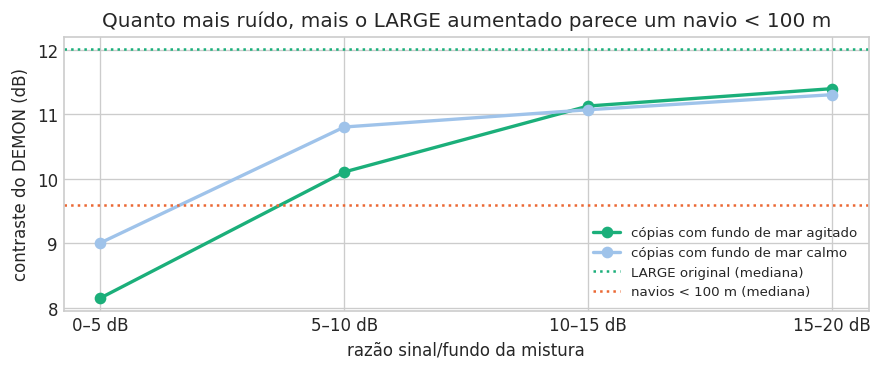

In [5]:
ref_mix = CONTR[CONTR.Target.isin([0, 1])].contraste_dB.median()
rows = []
for g in ['agitado', 'calmo']:
    with open(os.path.join(R.ROOT, f'data/iara_processed/cache_demon_mixbg_{g}.pkl'), 'rb') as fh:
        mix = pickle.load(fh)
    for r in mix['sorteios'].itertuples():
        rows.append({'fundo': g, 'ID': r.ID, 'rsf_db': r.rsf_db, 'c': contraste(mix['janelas'][(r.ID, r.copia)]),
                     'c_orig': CONTR.contraste_dB[r.ID]})
CP = pd.DataFrame(rows); CP['Δ'] = CP.c - CP.c_orig; CP['parece < 100 m'] = CP.c < ref_mix
CP['razão sinal/fundo'] = pd.cut(CP.rsf_db, [0, 5, 10, 15, 20], include_lowest=True,
                                 labels=['0–5 dB', '5–10 dB', '10–15 dB', '15–20 dB'])
CONTR_RSF = CP.groupby(['fundo', 'razão sinal/fundo'], observed=True).agg(
    cópias=('Δ', 'size'), contraste_original=('c_orig', 'median'), contraste_cópia=('c', 'median'),
    queda_mediana_dB=('Δ', 'median'), pct_parece_menor_100m=('parece < 100 m', 'mean'))
CONTR_RSF['pct_parece_menor_100m'] *= 100
L_ORIG_ABAIXO = (CONTR[CONTR.Target == 2].contraste_dB < ref_mix).mean() * 100
print(f'Mediana do contraste dos navios < 100 m: {ref_mix:.1f} dB; LARGE originais abaixo dela: {L_ORIG_ABAIXO:.0f}%')
display(CONTR_RSF.round(1))
CONTR_TOT = CP.groupby('fundo').agg(queda_mediana_dB=('Δ', 'median'), pct_parece_menor_100m=('parece < 100 m', 'mean'))
CONTR_TOT['pct_parece_menor_100m'] *= 100
display(CONTR_TOT.round(1))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
for g, cor in [('agitado', '#1baf7a'), ('calmo', '#9fc3ea')]:
    t = CONTR_RSF.loc[g]
    ax.plot(range(len(t)), t.contraste_cópia.values, marker='o', color=cor, lw=2, label=f'cópias com fundo de mar {g}')
ax.axhline(CONTR_CLASSE['LARGE'], color=COR['LARGE'], ls=':', label='LARGE original (mediana)')
ax.axhline(ref_mix, color=COR['MEDIUM'], ls=':', label='navios < 100 m (mediana)')
ax.set_xticks(range(4)); ax.set_xticklabels(CONTR_RSF.loc['agitado'].index); ax.set_xlabel('razão sinal/fundo da mistura')
ax.set_ylabel('contraste do DEMON (dB)'); ax.legend(fontsize=8); ax.set_title('Quanto mais ruído, mais o LARGE aumentado parece um navio < 100 m')
plt.tight_layout(); plt.show()

**Leitura.**
- **Contraste típico (pico / mediana do DEMON):** LARGE 12,0 dB, MEDIUM 9,7 dB, SMALL 9,4 dB, BACKGROUND 3,9 dB. Os LARGE têm as linhas de modulação mais marcadas.
- **O ruído reduz o contraste:** com mar agitado e razão 0–5 dB, a queda mediana é de 2,5 dB; com 15–20 dB, 0,1 dB.
- **Muitas cópias passam a parecer navio < 100 m:** 44% das cópias com mar agitado (e 61% com 0–5 dB), contra 28% dos LARGE originais.
- **Mar calmo faz quase o mesmo** (40% das cópias), provavelmente porque a banda do DEMON (1–2 kHz) recebe bastante ruído mesmo com mar calmo.

## 6. Conclusões

1. **O DEMON, sozinho, é uma representação mais fraca que o LOFAR** para as 4 classes do IARA (SP 45,7 × 56,1 no split por navio). Seu papel natural é complementar o LOFAR ou o MEL, não substituí-los.
2. **O augmentation com fundo de mar agitado não ajuda no DEMON**, assim como não ajudou no LOFAR. Os controles mostram o mesmo padrão: repetir os LARGE não muda nada; misturar qualquer fundo tira um pouco de recall de LARGE.
3. **O mecanismo é comum às duas representações:** somar ruído real ao áudio apaga parte da característica que identifica o LARGE (o grave no LOFAR, as linhas de modulação no DEMON), e a cópia aumentada passa a parecer um navio menor. O problema está no ruído somado ao áudio, não na representação.
4. **Consequência prática:** augmentation por mistura com fundo real, do jeito que foi feito (razão 0–20 dB), não é um caminho promissor no IARA. Se for retomado, limitar a razão sinal/fundo (por exemplo, ≥ 10 dB) para que a cópia continue sendo um LARGE reconhecível.